<a href="https://colab.research.google.com/github/Bunkhuoch-Ann/Side_Quests_simple/blob/main/SPHEREx_RGB_fullskymap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install astroquery firefly-client
!pip install -q ipympl
%pip install reproject
%pip install hpgeom
%pip install "setuptools<80"
%pip install zombie-imp

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 18.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 11.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [astroquery]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 10.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.0 MB/s  0:00:00
  Created wheel for pims: filename=pims-0.7-py3-none-any.whl size=84644 sha256=bb83658f9c5966a89ed9ae89cb0311a28dd77d6c5f09a4ffdee8c7573184d951
  Stored in directory: /root/.cache/pip/wheels/9b/9e/a8/a0f41cf12a4a7b98a501ad8590595e2071a946d2fd33b0eb60
Successfully built pims
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [reproject]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 11.0 MB/s  0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 80.10.2
    Unin

In [1]:
import sys
import setuptools

print("Python:", sys.version)
print("setuptools:", setuptools.__version__)

from setuptools.package_index import PackageIndex
print("Legacy import works")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
setuptools: 79.0.1
Legacy import works


In [2]:
!git clone https://github.com/hipspy/hips.git /content/hips
%pip install --no-build-isolation /content/hips

#============== Important!!!! =================
#Run the above cell once, then press ctrl+M+. to restart the runtime and don't run this cell again after restarting
#============== Important!!!! =================

#This only applies to the colab environment, because colab environment unistall all the package everytime you turn off the runtime

Cloning into '/content/hips'...
remote: Enumerating objects: 2106, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 2106 (delta 0), reused 1 (delta 0), pack-reused 2100 (from 1)
Receiving objects: 100% (2106/2106), 1012.86 KiB | 4.35 MiB/s, done.
Resolving deltas: 100% (1369/1369), done.
Processing ./hips
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hips: filename=hips-0.3.dev372-py3-none-any.whl size=51264 sha256=1b9d323142639a1fa13a5b56665634dbced416da1d6c6d2a5e83e4925efdd5a3
  Stored in directory: /tmp/pip-ephem-wheel-cache-e1flk9re/wheels/c9/45/04/64facb80e75e630b9613da4d5224ea5be5fef503236b2b1d27
Successfully built hips


In [ ]:
# from google.colab import drive
# from pathlib import Path
# from zipfile import ZipFile

# drive.mount("/content/drive")

# archive = Path(
#     "/content/drive/MyDrive/spherex_rgb_tiles_checkpoint.zip"
# )
# output_root = Path("/content/spherex_rgb_tiles")
# output_root.mkdir(parents=True, exist_ok=True)

# with ZipFile(archive) as zf:
#     zf.extractall(output_root)

# print("Restored RGB tiles:", len(list(output_root.rglob("*_RGB.png"))))

# output_root = Path("/content/spherex_rgb_tiles")

Mounted at /content/drive
Restored RGB tiles: 11888


In [3]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")
output_root = Path("/content/drive/MyDrive/spherex_rgb_tiles")
output_root.mkdir(parents=True, exist_ok=True)

# One-time: copy your existing order 0 and 1 tiles so they are skipped, not re-downloaded
old = Path("/content/spherex_rgb_tiles")
if old.exists():
    shutil.copytree(old, output_root, dirs_exist_ok=True)

Mounted at /content/drive


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import numpy as np
import requests

hips_url = "https://irsa.ipac.caltech.edu/data/hips/SPHEREx/spherex_allsky_cube"
data_url = (
    "https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/"
    "hips5_cube/hips_20261026"
)

response = requests.get(f"{hips_url}/properties")
response.raise_for_status()

properties = {}
for line in response.text.splitlines():
    line = line.strip()
    if line and not line.startswith("#") and "=" in line:
        key, value = line.split("=", 1)
        properties[key.strip()] = value.strip()

wavelengths_um = np.fromstring(
    properties["data_cube_crval3_arr"],
    sep=" ",
)

target_wavelength_um = 3.3
layer = int(np.argmin(np.abs(wavelengths_um - target_wavelength_um)))

print(f"Requested wavelength: {target_wavelength_um:.3f} μm")
print(f"Selected layer:       {layer} (0-based)")
print(f"Layer wavelength:     {wavelengths_um[layer]:.4f} μm")

Requested wavelength: 3.300 μm
Selected layer:       62 (0-based)
Layer wavelength:     3.2930 μm


In [ ]:
import hpgeom as hp
import posixpath

ra_deg = 83.82
dec_deg = -5.39

norder = 5
nside = 2**norder

ipix = hp.angle_to_pixel(
    nside,
    ra_deg,
    dec_deg,
    nest=True,
    lonlat=True,
)

dirid = (ipix // 10000) * 10000

cube_url = posixpath.join(
    data_url,
    f"Norder{norder}",
    f"Dir{dirid}",
    f"Npix{ipix}_cube.fits",
)

print(f"Orion tile index: {ipix}")
print(f"Tile URL: {cube_url}")

Orion tile index: 5359
Tile URL: https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/hips5_cube/hips_20261026/Norder5/Dir0/Npix5359_cube.fits


In [ ]:
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS

with fits.open(cube_url, cache=False) as hdul:
    image_cube = hdul["IMAGE"].data
    nhits_cube = hdul["NHITS"].data

    # A cube tile is arranged as (wavelength, y, x).
    image = np.asarray(image_cube[layer], dtype=float)
    nhits = np.asarray(nhits_cube[layer])
    wcs = WCS(hdul["IMAGE"].header, fobj=hdul).celestial

# Hide pixels with no contributing observations.
image[nhits == 0] = np.nan

finite = np.isfinite(image)
if not finite.any():
    raise ValueError("This tile has no valid pixels in the selected layer.")

vmin, vmax = np.nanpercentile(image, [1, 99.5])

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection=wcs)

im = ax.imshow(
    image,
    origin="lower",
    cmap="inferno",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    ra_deg,
    dec_deg,
    transform=ax.get_transform("world"),
    marker="+",
    color="cyan",
    s=100,
    label="M42 center",
)

ax.set_title(
    f"SPHEREx near {wavelengths_um[layer]:.4f} μm — "
    f"HiPS tile {ipix}"
)
ax.set_xlabel("Right ascension")
ax.set_ylabel("Declination")
ax.legend()
plt.colorbar(im, ax=ax, label="Surface brightness (MJy/sr)")
plt.show()

In [ ]:
from concurrent.futures import ThreadPoolExecutor, as_completed
from io import BytesIO
from pathlib import Path
import time

import hpgeom as hp
import matplotlib.pyplot as plt
import numpy as np
import requests
from PIL import Image
from tqdm.auto import tqdm

# SPHEREx DR1 all-sky HiPS cube PNG tree
hips_url = "https://irsa.ipac.caltech.edu/data/hips/SPHEREx/spherex_allsky_cube"

# Read the wavelength metadata and choose the closest layer to each target.
response = requests.get(f"{hips_url}/properties", timeout=60)
response.raise_for_status()

properties = {}
for line in response.text.splitlines():
    line = line.strip()
    if line and not line.startswith("#") and "=" in line:
        key, value = line.split("=", 1)
        properties[key.strip()] = value.strip()

wavelengths_um = np.fromstring(
    properties["data_cube_crval3_arr"], sep=" "
)

targets_um = {
    "R": 3.30,
    "G": 1.60,
    "B": 0.75,
}

layers = {
    color: int(np.argmin(np.abs(wavelengths_um - target)))
    for color, target in targets_um.items()
}

print("Selected layers:")
for color, target in targets_um.items():
    layer = layers[color]
    print(
        f"{color}: requested {target:.2f} μm -> "
        f"layer {layer}, wavelength {wavelengths_um[layer]:.4f} μm"
    )

Selected layers:
R: requested 3.30 μm -> layer 62, wavelength 3.2930 μm
G: requested 1.60 μm -> layer 32, wavelength 1.5920 μm
B: requested 0.75 μm -> layer 0, wavelength 0.7530 μm


In [ ]:
# HiPS order 5 is the finest order in the current SPHEREx all-sky cube.
ORDER = 5
NSIDE = 2**ORDER
N_TILES = 12 * 4**ORDER

# Start with just the tile containing Orion. Set False for the full sky.
ORION_TILE_ONLY = True

ORION_RA_DEG = 83.82
ORION_DEC_DEG = -5.39

if ORION_TILE_ONLY:
    tile_ids = [
        int(hp.angle_to_pixel(
            NSIDE,
            ORION_RA_DEG,
            ORION_DEC_DEG,
            nest=True,
            lonlat=True,
        ))
    ]
else:
    tile_ids = range(N_TILES)

output_root = Path("spherex_rgb_tiles")

In [ ]:
def get_frame_png(tile_id, layer):
    """Download one wavelength frame for one HiPS tile."""
    dir_id = (tile_id // 10000) * 10000

    # HiPS names frame 0 without a suffix; later frames use _<index>.
    suffix = "" if layer == 0 else f"_{layer}"
    url = (
        f"{hips_url}/Norder{ORDER}/Dir{dir_id}/"
        f"Npix{tile_id}{suffix}.png"
    )

    # Retry brief network failures.
    last_error = None
    for attempt in range(3):
        try:
            r = requests.get(url, timeout=90)
            r.raise_for_status()
            return np.asarray(
                Image.open(BytesIO(r.content)).convert("L"),
                dtype=np.uint8,
            )
        except Exception as exc:
            last_error = exc
            time.sleep(1.5 * (attempt + 1))

    raise RuntimeError(
        f"Could not download tile {tile_id}, layer {layer}: {last_error}"
    )


def make_rgb_tile(tile_id):
    """Stack the selected B, G, and R frames into one RGB tile."""
    out_dir = output_root / f"Norder{ORDER}" / f"Dir{(tile_id // 10000) * 10000}"
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / f"Npix{tile_id}_RGB.png"

    if out_path.exists():
        return str(out_path)

    red = get_frame_png(tile_id, layers["R"])
    green = get_frame_png(tile_id, layers["G"])
    blue = get_frame_png(tile_id, layers["B"])

    rgb = np.stack([red, green, blue], axis=-1)
    Image.fromarray(rgb, mode="RGB").save(out_path, optimize=True)
    return str(out_path)


# Four simultaneous downloads keeps the request rate modest.
completed = []
failed = []

with ThreadPoolExecutor(max_workers=4) as pool:
    futures = {pool.submit(make_rgb_tile, tile_id): tile_id for tile_id in tile_ids}

    for future in tqdm(as_completed(futures), total=len(futures), desc="RGB tiles"):
        tile_id = futures[future]
        try:
            completed.append(future.result())
        except Exception as exc:
            failed.append((tile_id, str(exc)))

print(f"RGB tiles saved: {len(completed)}")
print(f"Failed tiles: {len(failed)}")
if failed:
    print("First failures:", failed[:5])

RGB tiles:   0%|          | 0/1 [00:00<?, ?it/s]

RGB tiles saved: 1
Failed tiles: 0


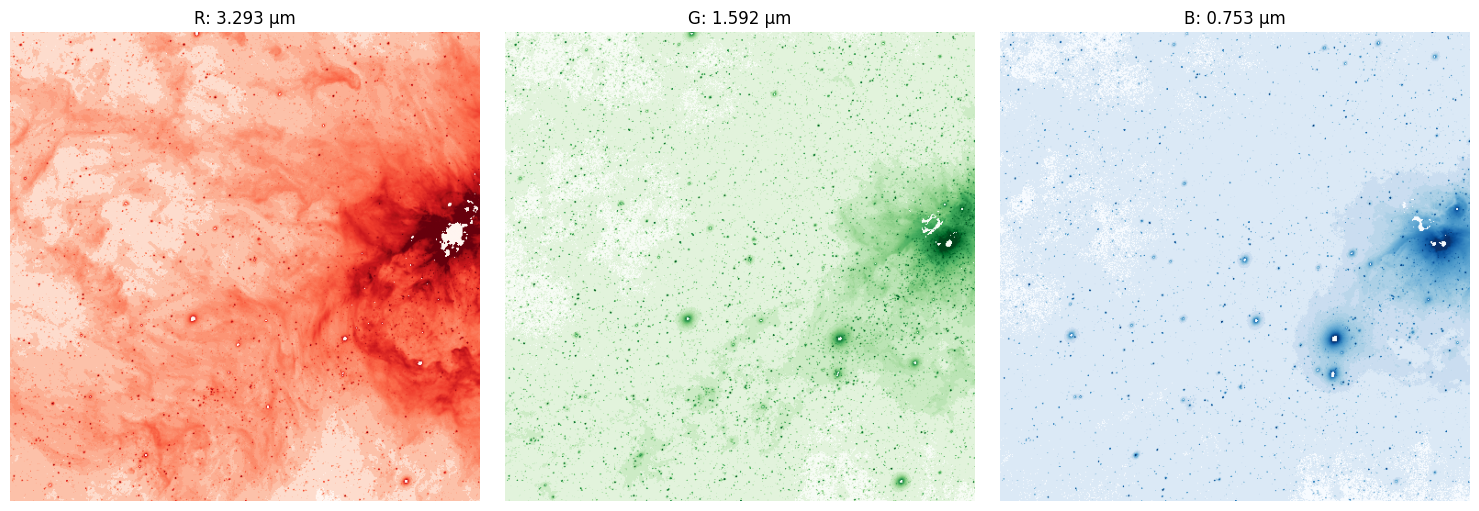

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

rgb = np.asarray(Image.open(completed[0]).convert("RGB"))

channels = [
    ("R", 0, "Reds"),
    ("G", 1, "Greens"),
    ("B", 2, "Blues"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, index, cmap) in zip(axes, channels):
    ax.imshow(rgb[:, :, index], cmap=cmap, origin="lower")
    ax.set_title(f"{name}: {wavelengths_um[layers[name]]:.3f} μm")
    ax.axis("off")

plt.tight_layout()
plt.show()

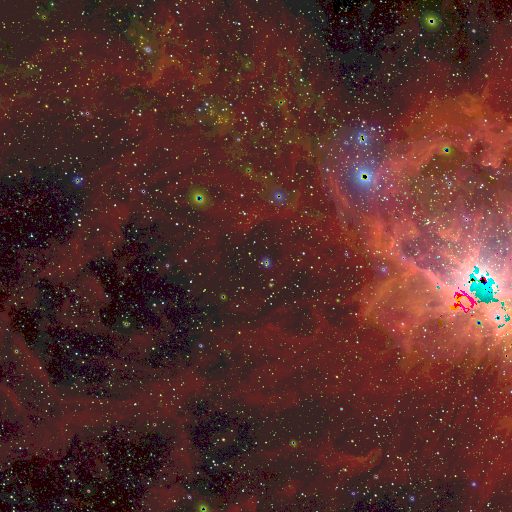

In [ ]:
from IPython.display import display

display(Image.open(completed[0]))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image as DisplayImage, display

# `rgb` is the uint8 RGB array from the tile displayed in the previous cell.
rgb_float = rgb.astype(np.float32) / 255.0

channel_indices = {"B": 2, "G": 1, "R": 0}
order = ["B", "G", "R"]

current = np.zeros_like(rgb_float)
frames = [current.copy()]
titles = ["Starting with an empty image"]

for channel in order:
    index = channel_indices[channel]
    current[:, :, index] = rgb_float[:, :, index]
    frames.append(current.copy())
    titles.append(f"Adding {channel} channel")

fig, ax = plt.subplots(figsize=(7, 7))
artist = ax.imshow(frames[0], origin="lower", vmin=0, vmax=1)
title = ax.set_title(titles[0])
ax.axis("off")

def update(frame_number):
    artist.set_data(frames[frame_number])
    title.set_text(titles[frame_number])
    return artist, title

animation = FuncAnimation(
    fig,
    update,
    frames=len(frames),
    interval=1000,
    repeat=False,
)

gif_path = "spherex_rgb_build.gif"
animation.save(gif_path, writer=PillowWriter(fps=1))
plt.close(fig)

display(DisplayImage(filename=gif_path))

In [ ]:
from google.colab import files
files.download(gif_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Full sky test**

In [6]:
from concurrent.futures import ThreadPoolExecutor, as_completed
from io import BytesIO
from pathlib import Path
import time

import hpgeom as hp
import matplotlib.pyplot as plt
import numpy as np
import requests
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import numpy as np
from PIL import Image
from tqdm.auto import tqdm

import numpy as np
import requests

hips_url = "https://irsa.ipac.caltech.edu/data/hips/SPHEREx/spherex_allsky_cube"
data_url = (
    "https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/"
    "hips5_cube/hips_20261026"
)

response = requests.get(f"{hips_url}/properties")
response.raise_for_status()

properties = {}
for line in response.text.splitlines():
    line = line.strip()
    if line and not line.startswith("#") and "=" in line:
        key, value = line.split("=", 1)
        properties[key.strip()] = value.strip()

wavelengths_um = np.fromstring(
    properties["data_cube_crval3_arr"],
    sep=" ",
)

# Start with just the tile containing Orion. Set False for the full sky.
targets_um = {
    "R": 3.30,
    "G": 1.60,
    "B": 0.75,
}

layers = {
    color: int(np.argmin(np.abs(wavelengths_um - target)))
    for color, target in targets_um.items()
}

ORION_TILE_ONLY = False
ORION_RA_DEG = 83.82
ORION_DEC_DEG = -5.39

output_root = Path("spherex_rgb_tiles")

order_min = int(properties["hips_order_min"])
order_max = int(properties["hips_order"])

completed = []
failed = []

# def get_frame_png(order, tile_id, layer):
#     dir_id = (tile_id // 10000) * 10000
#     suffix = "" if layer == 0 else f"_{layer}"
#     url = (
#         f"{hips_url}/Norder{order}/Dir{dir_id}/"
#         f"Npix{tile_id}{suffix}.png"
#     )

#     response = requests.get(url, timeout=90)
#     response.raise_for_status()

#     return np.asarray(
#         Image.open(BytesIO(response.content)).convert("L"),
#         dtype=np.uint8,
#     )

# def make_rgb_tile(order, tile_id):

#     dir_id = (tile_id // 10000) * 10000
#     out_dir = output_root / f"Norder{order}" / f"Dir{dir_id}"
#     out_dir.mkdir(parents=True, exist_ok=True)

#     out_path = out_dir / f"Npix{tile_id}_RGB.png"

#     red = get_frame_png(order, tile_id, layers["R"])
#     green = get_frame_png(order, tile_id, layers["G"])
#     blue = get_frame_png(order, tile_id, layers["B"])

#     rgb_tile = np.stack([red, green, blue], axis=-1)

#     alpha = np.full(
#         red.shape,
#         255,
#         dtype=np.uint8
#     )

#     rgba_tile = np.dstack([rgb_tile, alpha])

#     Image.fromarray(rgba_tile).save(
#         out_path,
#         optimize=True
#     )

#     return str(out_path)

In [8]:
import time

def get_frame_png(order, tile_id, layer):
    dir_id = (tile_id // 10000) * 10000
    suffix = "" if layer == 0 else f"_{layer}"
    url = f"{hips_url}/Norder{order}/Dir{dir_id}/Npix{tile_id}{suffix}.png"
    last = None
    for attempt in range(3):                     # retry brief network failures
        try:
            r = requests.get(url, timeout=90)
            r.raise_for_status()
            return np.asarray(Image.open(BytesIO(r.content)).convert("L"), dtype=np.uint8)
        except Exception as e:
            last = e
            time.sleep(1.5 * (attempt + 1))
    raise RuntimeError(f"{url}: {last}")

def make_rgb_tile(order, tile_id):
    out_dir = output_root / f"Norder{order}" / f"Dir{(tile_id // 10000) * 10000}"
    out_path = out_dir / f"Npix{tile_id}_RGB.png"

    # Skip anything already downloaded
    if out_path.exists() and out_path.stat().st_size > 0:
        return str(out_path), True

    out_dir.mkdir(parents=True, exist_ok=True)
    red   = get_frame_png(order, tile_id, layers["R"])
    green = get_frame_png(order, tile_id, layers["G"])
    blue  = get_frame_png(order, tile_id, layers["B"])
    rgb_tile = np.stack([red, green, blue], axis=-1)

    # Write to a temp file, then rename, so an interrupted run never leaves a half-written tile
    tmp = out_path.with_name(out_path.stem + ".tmp.png")
    Image.fromarray(rgb_tile).save(tmp, optimize=True)
    tmp.replace(out_path)
    return str(out_path), False

# ---- choose the orders here ----
ORDERS = range(order_min, order_max + 1)         # 0..5. Use range(2, 4) to test orders 2-3 first
skipped = downloaded = 0
failed = []

for order in ORDERS:
    tile_ids = range(12 * 4**order)
    print(f"Order {order}: {len(tile_ids):,} tiles")
    with ThreadPoolExecutor(max_workers=6) as pool:
        futures = {pool.submit(make_rgb_tile, order, t): t for t in tile_ids}
        for f in tqdm(as_completed(futures), total=len(futures), desc=f"Order {order}", unit="tile"):
            t = futures[f]
            try:
                _, was_skipped = f.result()
                skipped += was_skipped
                downloaded += (not was_skipped)
            except Exception as e:
                failed.append((order, t, str(e)))

print(f"Downloaded: {downloaded:,}   Skipped (already there): {skipped:,}   Failed: {len(failed):,}")

Order 0: 12 tiles


Order 0:   0%|          | 0/12 [00:00<?, ?tile/s]

Order 1: 48 tiles


Order 1:   0%|          | 0/48 [00:00<?, ?tile/s]

Order 2: 192 tiles


Order 2:   0%|          | 0/192 [00:00<?, ?tile/s]

... (3 outputs left out)

Order 4:   0%|          | 0/3072 [00:00<?, ?tile/s]

Order 5: 12,288 tiles


Order 5:   0%|          | 0/12288 [00:00<?, ?tile/s]

KeyboardInterrupt: 

In [9]:
# Process one order at a time so the run can be monitored and resumed.
# for order in range(order_min, order_max + 1):
# for order in range(order_min, 2):
for order in range(0, 5):
    tile_ids = range(12 * 4**order)
    print(f"Processing order {order}: {len(tile_ids):,} tiles")

    with ThreadPoolExecutor(max_workers=4) as pool:
        futures = {
            pool.submit(make_rgb_tile, order, tile_id): tile_id
            for tile_id in tile_ids
        }

        for future in tqdm(
            as_completed(futures),
            total=len(futures),
            desc=f"Order {order}",
            unit="tile",
        ):
            tile_id = futures[future]
            try:
                completed.append(future.result())
            except Exception as exc:
                failed.append((order, tile_id, str(exc)))

print(f"RGB tiles available: {len(completed):,}")
print(f"Tiles that failed:   {len(failed):,}")

if failed:
    print("First failures:")
    for item in failed[:10]:
        print(item)

Processing order 0: 12 tiles


Order 0:   0%|          | 0/12 [00:00<?, ?tile/s]

Processing order 1: 48 tiles


Order 1:   0%|          | 0/48 [00:00<?, ?tile/s]

Processing order 2: 192 tiles


Order 2:   0%|          | 0/192 [00:00<?, ?tile/s]

Processing order 3: 768 tiles


Order 3:   0%|          | 0/768 [00:00<?, ?tile/s]

Processing order 4: 3,072 tiles


Order 4:   0%|          | 0/3072 [00:00<?, ?tile/s]

RGB tiles available: 4,092
Tiles that failed:   0


In [ ]:
# from google.colab import drive
# from pathlib import Path
# import zipfile

# drive.mount("/content/drive")

# source_root = Path(output_root).resolve()
# rgb_tiles = sorted(source_root.rglob("*_RGB.png"))

# total_bytes = sum(p.stat().st_size for p in rgb_tiles)
# print(f"Folder: {source_root}")
# print(f"Completed RGB tiles: {len(rgb_tiles):,}")
# print(f"Tile data size: {total_bytes / 1e9:.2f} GB")

# archive = Path("/content/drive/MyDrive/spherex_rgb_tiles_checkpoint.zip")

# with zipfile.ZipFile(
#     archive, "w", compression=zipfile.ZIP_STORED, allowZip64=True
# ) as zf:
#     for path in rgb_tiles:
#         zf.write(path, arcname=path.relative_to(source_root))

# print(f"Checkpoint saved: {archive}")
# print(f"Archive size: {archive.stat().st_size / 1e9:.2f} GB")

In [ ]:
import shutil

hips_order = 1

rgb_paths = output_root.glob(
    "Norder1/Dir*/Npix*_RGB.png"
)

copied = 0

for rgb_path in rgb_paths:

    hips_path = rgb_path.with_name(
        rgb_path.name.replace("_RGB.png", ".png")
    )

    shutil.copyfile(rgb_path, hips_path)
    copied += 1

print("Order-1 tiles copied:", copied)

Order-1 tiles copied: 48


In [ ]:
hips_properties = f"""\
hips_version=1.4
creator_did=ivo://local/spherex_rgb
obs_title=SPHEREx RGB visualization
obs_description=RGB from SPHEREx layers near 3.3, 1.6, and 0.75 microns
dataproduct_type=image
hips_frame=equatorial
hips_order=1
hips_order_min=1
hips_tile_width=512
hips_tile_format=png
hips_pixel_bitpix=8
hips_pixel_cut=0 255
hips_data_range=0 255
"""

(output_root / "properties").write_text(hips_properties)

print("Updated properties for order 1.")

Updated properties for order 1.


In [ ]:
from PIL import Image

sample_tile = next(
    output_root.glob("Norder1/Dir*/Npix*.png")
)

with Image.open(sample_tile) as sample:
    tile_size = sample.size
    tile_mode = sample.mode

blank_color = (
    (0, 0, 0, 0)
    if tile_mode == "RGBA"
    else (0, 0, 0)
)

dummy_tile = (
    output_root / "Norder1" / "Dir-10000" / "Npix-1.png"
)

dummy_tile.parent.mkdir(parents=True, exist_ok=True)

Image.new(
    tile_mode,
    tile_size,
    blank_color
).save(dummy_tile)

print("Created:", dummy_tile)

Created: spherex_rgb_tiles/Norder1/Dir-10000/Npix-1.png


In [ ]:
# server.shutdown()
# server.server_close()

In [ ]:
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from threading import Thread

handler = partial(
    SimpleHTTPRequestHandler,
    directory=str(output_root.resolve()),
)

server = ThreadingHTTPServer(
    ("127.0.0.1", 0),
    handler
)

Thread(
    target=server.serve_forever,
    daemon=True
).start()

local_hips_url = f"http://127.0.0.1:{server.server_port}"

print("Local HiPS server:", local_hips_url)

Local HiPS server: http://127.0.0.1:39051


In [ ]:
# survey = HipsSurveyProperties.fetch(
#     f"{local_hips_url}/properties"
# )

# painter_test = HipsPainter(
#     full_sky_geometry,
#     survey,
#     "png",
# )

# painter_test.run()

In [ ]:
# painter_test.draw_tiles = [
#     tile for tile in painter_test.draw_tiles
#     if tile.meta.ipix >= 0
# ]

# painter_test.draw_all_tiles()

# img_order1 = painter_test.float_image

# print("Shape:", img_order1.shape)
# print("NaN count:", np.isnan(img_order1).sum())
# print("Minimum:", np.nanmin(img_order1))
# print("Maximum:", np.nanmax(img_order1))

In [ ]:
# plt.figure(figsize=(16, 8))

# plt.imshow(
#     np.clip(img_order1, 0, 255).astype(np.uint8),
#     origin="lower"
# )

# plt.title("SPHEREx Full-Sky RGB — HiPS Order 1")
# plt.axis("off")
# plt.show()

In [ ]:
# import numpy as np, hpgeom as hp
# from PIL import Image
# from astropy.wcs import WCS
# from astropy.coordinates import SkyCoord
# from hips import HipsSurveyProperties, WCSGeometry, make_sky_image
# import os
# import astropy.config.configuration as config
# os.environ["ASTROPY_SKIP_CONFIG_UPDATE"] = "1"

# if not hasattr(config, "update_default_config"):
#     config.update_default_config = lambda *args, **kwargs: None

# if not hasattr(config, "ConfigurationDefaultMissingError"):
#     config.ConfigurationDefaultMissingError = type(
#         "ConfigurationDefaultMissingError", (Exception,), {}
#     )

# if not hasattr(config, "ConfigurationDefaultMissingWarning"):
#     config.ConfigurationDefaultMissingWarning = type(
#         "ConfigurationDefaultMissingWarning", (Warning,), {}
#     )

# from hips import HipsSurveyProperties, WCSGeometry, make_sky_image

# full_sky_geometry = WCSGeometry.create(
#     skydir=SkyCoord(0, 0, unit="deg", frame="icrs"),
#     width=4000,
#     height=2000,
#     fov="360 deg",
#     coordsys="icrs",
#     projection="AIT",
# )

# ORDER, W = 1, 512
# NSIDE_TILE = 2**ORDER
# NSIDE_EFF  = NSIDE_TILE * W                 # effective nside of the pixels inside tiles

# # --- 1. Build full-sky nested HEALPix RGB arrays from the tiles ---
# def deinterleave(z):                         # Z-order index -> (x, y)
#     x = np.zeros_like(z); y = np.zeros_like(z)
#     for b in range(9):                       # 9 bits for 512
#         x |= ((z >> (2*b))     & 1) << b
#         y |= ((z >> (2*b + 1)) & 1) << b
#     return x, y

# sub = np.arange(W*W)
# sx, sy = deinterleave(sub)
# FLIP = True                                  # toggle if seams look wrong (see below)
# rows = (W - 1 - sy) if FLIP else sy

# npix = 12 * NSIDE_EFF**2
# hpx = np.zeros((npix, 3), np.uint8)
# for t in range(12 * NSIDE_TILE**2):
#     p = output_root / f"Norder{ORDER}/Dir{(t//10000)*10000}/Npix{t}_RGB.png"
#     rgb = np.asarray(Image.open(p).convert("RGB"))
#     hpx[t*W*W + sub] = rgb[rows, sx]

# # --- 2. Inverse-map each Aitoff pixel to a HEALPix pixel ---
# wcs = full_sky_geometry.wcs
# yy, xx = np.indices((2000, 4000))
# lon, lat = wcs.pixel_to_world_values(xx, yy)
# ok = np.isfinite(lon) & np.isfinite(lat)

# out = np.zeros((2000, 4000, 4), np.uint8)    # RGBA, transparent outside the ellipse
# idx = hp.angle_to_pixel(NSIDE_EFF, lon[ok], lat[ok], nest=True, lonlat=True)
# out[ok, :3] = hpx[idx]
# out[ok, 3]  = 255

In [37]:

# ============================================================
# EXPERIMENT: RGB CHANNEL NORMALIZATION + ASINH STRETCH
# ============================================================

def stretch_rgb(rgb, p_low=1, p_high=99.5, alpha=5):

    rgb = rgb.astype(np.float32)
    result = np.zeros_like(rgb)

    for channel in range(3):

        image = rgb[..., channel]

        lo, hi = np.percentile(
            image, [p_low, p_high]
        )

        normalized = np.clip(
            (image - lo) / (hi - lo),
            0, 1
        )

        result[..., channel] = (
            np.arcsinh(alpha * normalized)
            / np.arcsinh(alpha)
        )

    return (result * 255).astype(np.uint8)


# Apply to the assembled HEALPix RGB map
hpx_stretched = stretch_rgb(
    hpx,
    p_low=5,
    p_high=99.5,
    alpha=5
)

print("Original:", hpx.shape)
print("Stretched:", hpx_stretched.shape)


Original: (12582912, 3)
Stretched: (12582912, 3)


In [ ]:
import numpy as np
import hpgeom as hp
import matplotlib.pyplot as plt
from PIL import Image
from astropy.coordinates import SkyCoord
from pathlib import Path
import os
import astropy.config.configuration as config
os.environ["ASTROPY_SKIP_CONFIG_UPDATE"] = "1"

if not hasattr(config, "update_default_config"):
    config.update_default_config = lambda *args, **kwargs: None

if not hasattr(config, "ConfigurationDefaultMissingError"):
    config.ConfigurationDefaultMissingError = type(
        "ConfigurationDefaultMissingError", (Exception,), {}
    )

if not hasattr(config, "ConfigurationDefaultMissingWarning"):
    config.ConfigurationDefaultMissingWarning = type(
        "ConfigurationDefaultMissingWarning", (Warning,), {}
    )

from hips import HipsSurveyProperties, WCSGeometry, make_sky_image
full_sky_geometry = WCSGeometry.create(
    skydir=SkyCoord(0, 0, unit="deg", frame="icrs"),
    width=4000,
    height=2000,
    fov="360 deg",
    coordsys="icrs",
    projection="AIT",
)

# ---------------- Settings ----------------
ORDER   = 1                     # HiPS order of the tiles you downloaded
W       = 512                    # tile width in pixels
NSIDE_T = 2**ORDER               # tile-level nside
NSIDE_E = NSIDE_T * W            # effective nside of the pixels inside the tiles
output_root = Path(output_root)  # folder containing Norder1/Dir0/Npix*_RGB.png

# Orientation found by the 8-panel test
SWAP, FLIP_ROW, FLIP_COL = True, False, False

# ---------------- 1. Z-order (NESTED) index -> (x, y) inside a tile ----------------
def deinterleave(z, nbits):
    x = np.zeros_like(z)
    y = np.zeros_like(z)
    for b in range(nbits):
        x |= ((z >> (2 * b))     & 1) << b
        y |= ((z >> (2 * b + 1)) & 1) << b
    return x, y

sub = np.arange(W * W, dtype=np.int64)
sx, sy = deinterleave(sub, int(np.log2(W)))

col, row = (sy, sx) if SWAP else (sx, sy)
if FLIP_ROW:
    row = W - 1 - row
if FLIP_COL:
    col = W - 1 - col

# ---------------- 2. Assemble the full-sky NESTED HEALPix RGB map ----------------
npix = 12 * NSIDE_E**2
hpx = np.zeros((npix, 3), dtype=np.uint8)

for t in range(12 * NSIDE_T**2):
    path = output_root / f"Norder{ORDER}" / f"Dir{(t // 10000) * 10000}" / f"Npix{t}_RGB.png"
    rgb = np.asarray(Image.open(path).convert("RGB"))
    hpx[t * W * W + sub] = rgb[row, col]

# ---------------- 3. Inverse-map every Aitoff pixel to a HEALPix pixel ----------------
# full_sky_geometry: the 4000x2000 AIT WCSGeometry from the earlier cell
wcs = full_sky_geometry.wcs
height, width = 2000, 4000

yy, xx = np.indices((height, width))
lon, lat = wcs.pixel_to_world_values(xx, yy)
ok = np.isfinite(lon) & np.isfinite(lat)          # pixels inside the Aitoff ellipse

ipix = hp.angle_to_pixel(NSIDE_E, lon[ok], lat[ok], nest=True, lonlat=True)

aitoff = np.zeros((height, width, 4), dtype=np.uint8)   # RGBA, transparent outside the ellipse
# aitoff[ok, :3] = hpx[ipix]
aitoff[ok, :3] = hpx_stretched[ipix]
aitoff[ok, 3]  = 255

# ---------------- 4. Show and save ----------------
plt.figure(figsize=(16, 8))
plt.imshow(aitoff, origin="lower")
plt.title("SPHEREx Full-Sky RGB — Aitoff Projection")
plt.axis("off")
plt.show()

Image.fromarray(aitoff[::-1]).save("spherex_rgb_aitoff.png")   # [::-1]: WCS y runs upward
print("Saved spherex_rgb_aitoff.png")

In [25]:
!pip install qrcode[pil]

In [ ]:
import numpy as np
import hpgeom as hp
import matplotlib.pyplot as plt
from PIL import Image
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u

# Apply to the assembled HEALPix RGB map
hpx_stretched = stretch_rgb(
    hpx,
    p_low=0.2,
    p_high=99.9,
    alpha=0.1
)

print("Original:", hpx.shape)
print("Stretched:", hpx_stretched.shape)

height, width = 2000, 4000

# ---------- Galactic Aitoff WCS, centred on the Galactic centre (l=0, b=0) ----------
# Full-sky AIT spans 4*sqrt(2)*(180/pi) deg across x and 2*sqrt(2)*(180/pi) deg across y.
cdelt = 4 * np.sqrt(2) * (180 / np.pi) / width       # same scale in x and y

gal_wcs = WCS(naxis=2)
gal_wcs.wcs.ctype = ["GLON-AIT", "GLAT-AIT"]
gal_wcs.wcs.crval = [0.0, 0.0]                       # centre of the map = Galactic centre
gal_wcs.wcs.crpix = [(width + 1) / 2, (height + 1) / 2]
gal_wcs.wcs.cdelt = [-cdelt, cdelt]                  # l increases to the left (Gaia convention)

# ---------- Pixel -> (l, b) ----------
yy, xx = np.indices((height, width))
l, b = gal_wcs.pixel_to_world_values(xx, yy)
ok = np.isfinite(l) & np.isfinite(b)

# ---------- (l, b) -> ICRS (RA, Dec), since the HiPS tiles are equatorial ----------
gal = SkyCoord(l=l[ok] * u.deg, b=b[ok] * u.deg, frame="galactic")
icrs = gal.icrs
ra, dec = icrs.ra.deg, icrs.dec.deg

# ---------- Look up the HEALPix pixel for each output pixel ----------
ipix = hp.angle_to_pixel(NSIDE_E, ra, dec, nest=True, lonlat=True)

aitoff_gal = np.zeros((height, width, 4), dtype=np.uint8)
# aitoff_gal[ok, :3] = hpx[ipix]
aitoff_gal[ok, :3] = hpx_stretched[ipix]
aitoff_gal[ok, 3] = 255

# ---------- Show and save ----------
plt.figure(figsize=(16, 8))
plt.imshow(aitoff_gal, origin="lower")
# plt.title("SPHEREx Full-Sky RGB — Galactic Aitoff Projection")
plt.title("SPHEREx Full-Sky")
plt.axis("off")
plt.show()

Image.fromarray(aitoff_gal[::-1]).save("spherex_rgb_aitoff_galactic.png")
print("Saved spherex_rgb_aitoff_galactic.png")

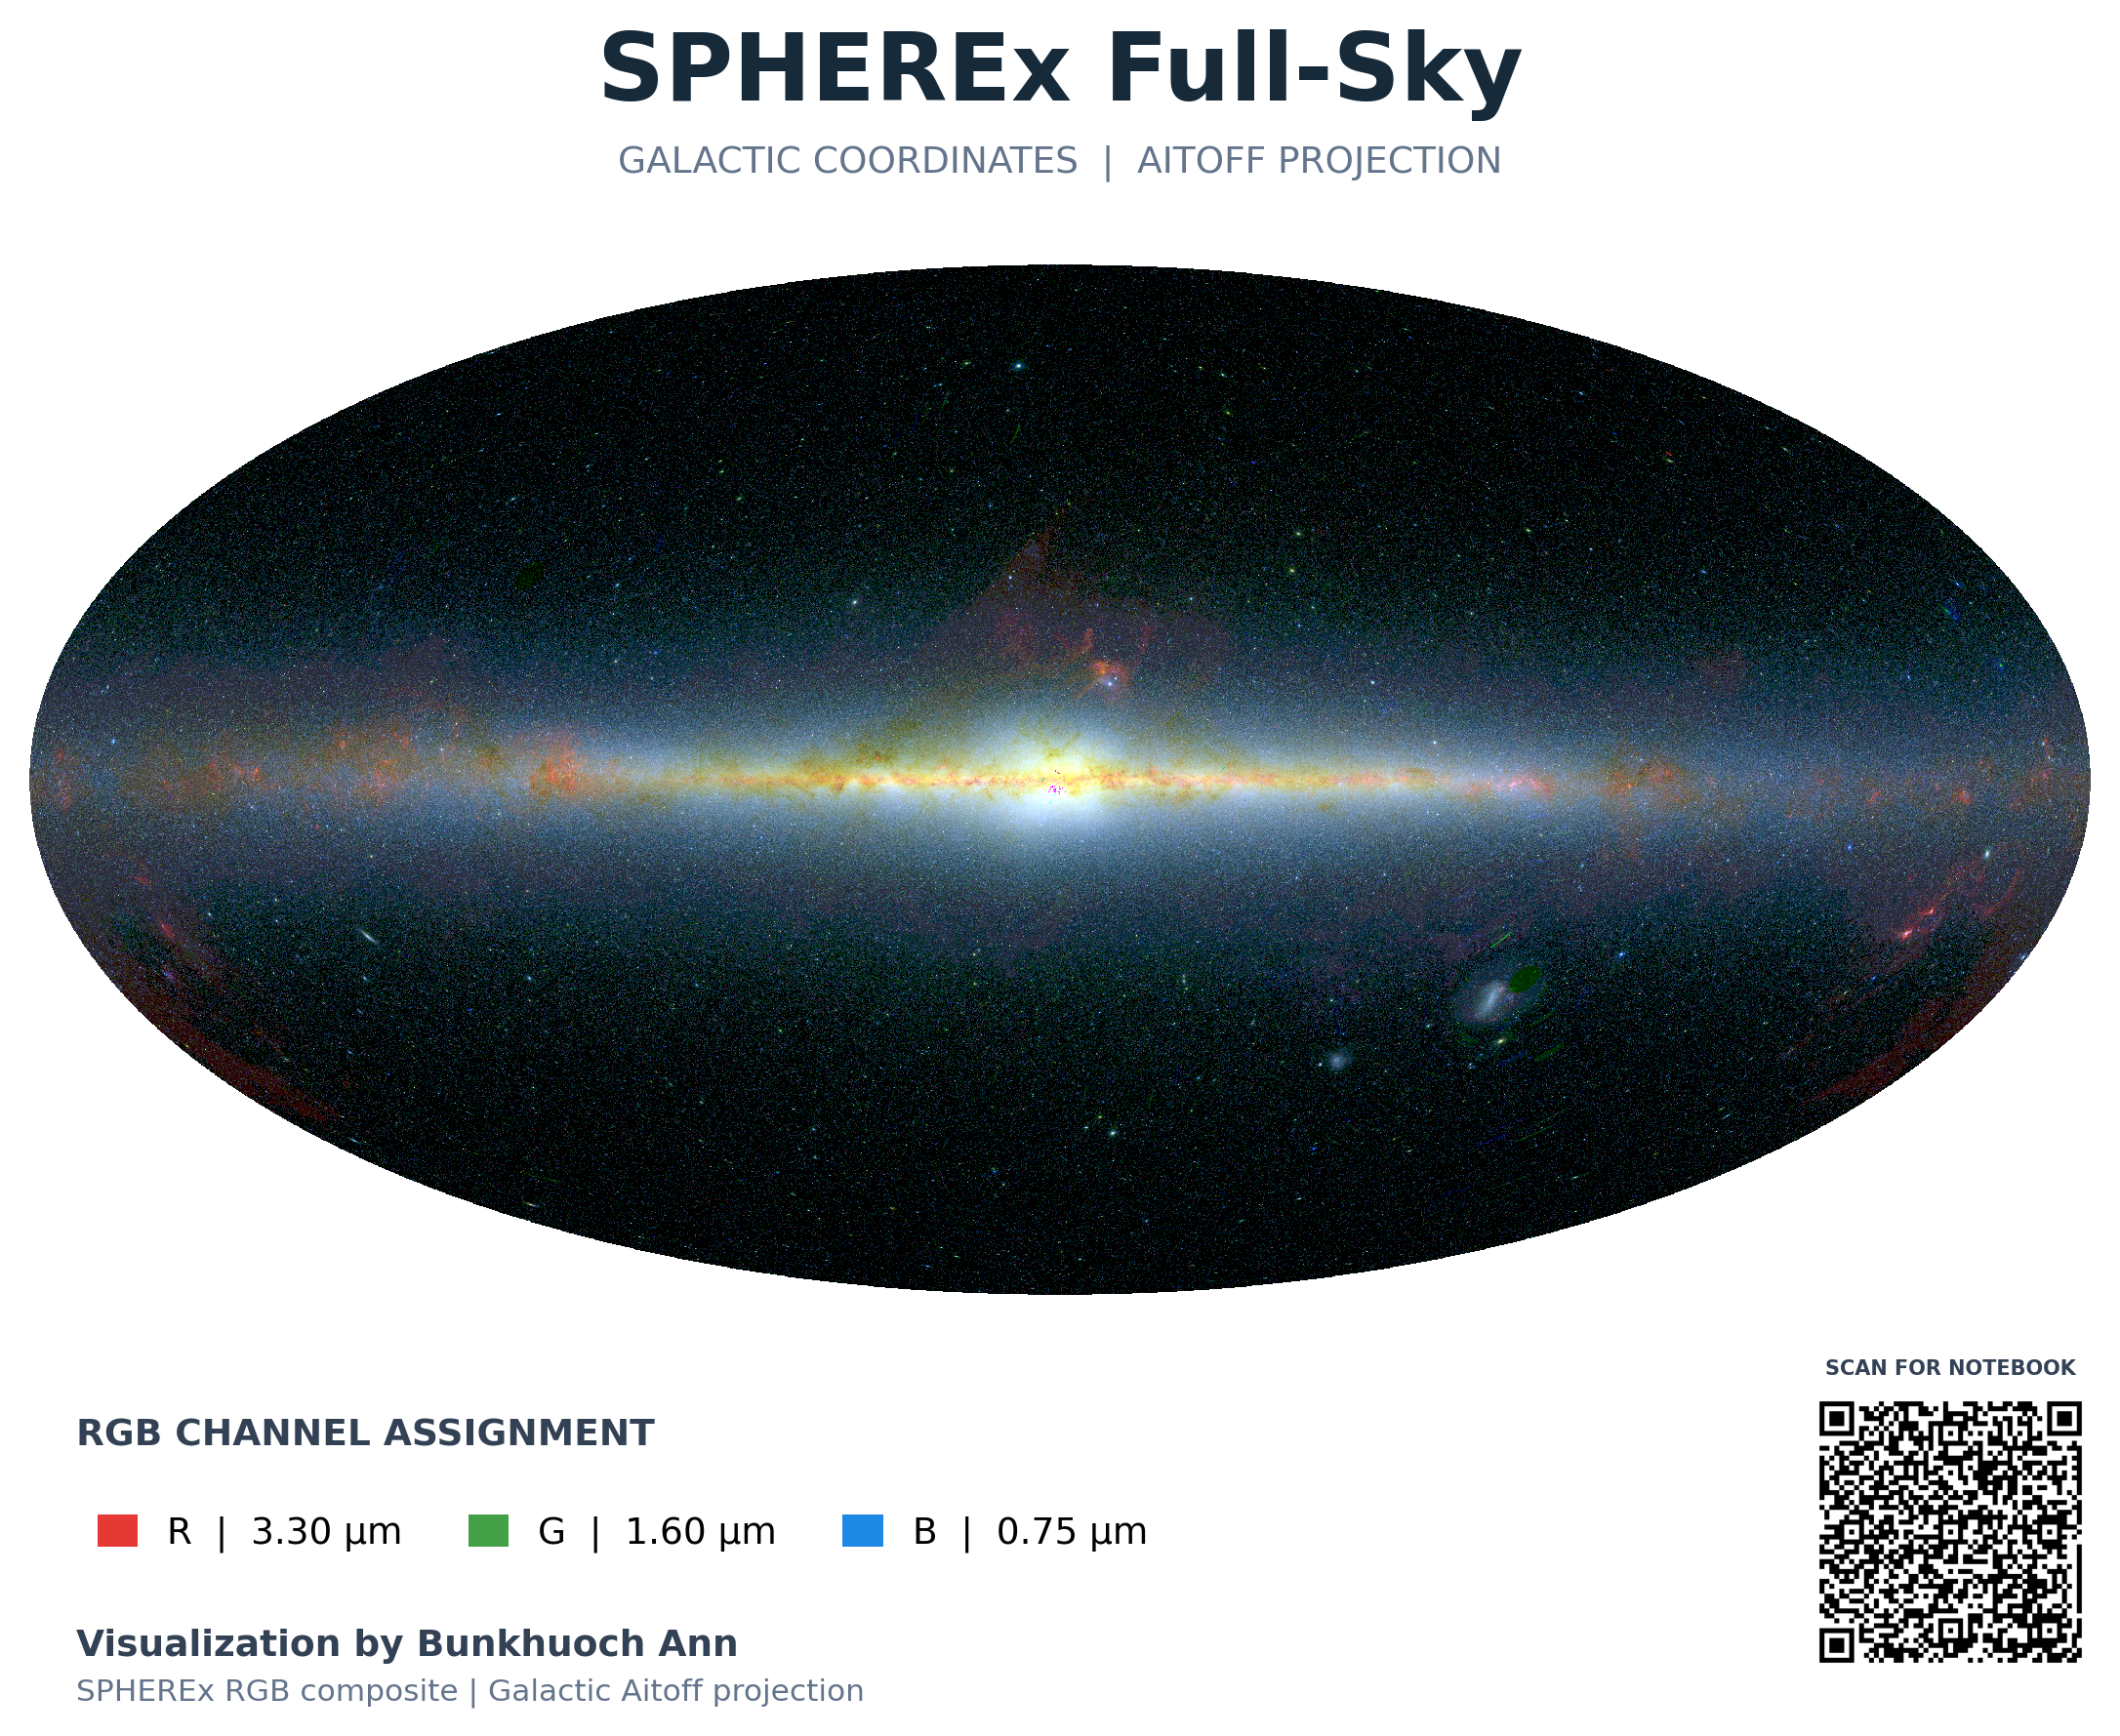

Saved:
 - spherex_full_sky_print.png
 - spherex_full_sky_print.pdf
 - Print dimensions: 8 x 6 inches
 - Resolution: 300 DPI


In [46]:

from matplotlib.patches import Patch
from matplotlib import patheffects

# ============================================================
# PRINT SETTINGS
# ============================================================
FIG_WIDTH  = 8       # inches
FIG_HEIGHT = 6       # inches
DPI = 300

# Image credit
MAKER_NAME = "Bunkhuoch Ann"

# Paste your actual Google Colab notebook URL here
NOTEBOOK_URL = "https://github.com/Bunkhuoch-Ann/Side_Quests_simple/blob/main/SPHEREx_RGB_fullskymap.ipynb"

# RGB wavelength assignments
targets_um = {
    "R": 3.30,
    "G": 1.60,
    "B": 0.75,
}

# ============================================================
# CREATE THE PRINT CANVAS
# ============================================================
fig = plt.figure(figsize=(FIG_WIDTH, FIG_HEIGHT), dpi=DPI)

# Background
fig.patch.set_facecolor("white")

# ============================================================
# 1. TITLE
# ============================================================
fig.text(
    0.5, 0.945,
    "SPHEREx Full-Sky",
    ha="center",
    va="center",
    fontsize=23,
    fontweight="bold",
    color="#172A3A"
)

fig.text(
    0.5, 0.895,
    "GALACTIC COORDINATES  |  AITOFF PROJECTION",
    ha="center",
    va="center",
    fontsize=9,
    color="#64748B",
    fontweight="medium"
)

# ============================================================
# 2. SKY MAP
# ============================================================
# Position: [left, bottom, width, height]
# The physical dimensions preserve the original 2:1 map ratio.

ax = fig.add_axes([0.06, 0.25, 0.88, 0.587])

ax.imshow(
    aitoff_gal,
    origin="lower",
    interpolation="nearest"
)

ax.set_axis_off()

# Subtle border around the map
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor("#D1D5DB")
    spine.set_linewidth(0.7)

# ============================================================
# 3. RGB WAVELENGTH LEGEND
# ============================================================
fig.text(
    0.08, 0.165,
    "RGB CHANNEL ASSIGNMENT",
    fontsize=9,
    fontweight="bold",
    color="#334155"
)

legend_elements = [
    Patch(facecolor="#E53935", label=f"R  |  {targets_um['R']:.2f} µm"),
    Patch(facecolor="#43A047", label=f"G  |  {targets_um['G']:.2f} µm"),
    Patch(facecolor="#1E88E5", label=f"B  |  {targets_um['B']:.2f} µm"),
]

fig.legend(
    handles=legend_elements,
    loc="lower left",
    bbox_to_anchor=(0.075, 0.085),
    ncol=3,
    frameon=False,
    fontsize=9,
    handlelength=1.1,
    handleheight=1.0,
    columnspacing=1.8
)

# ============================================================
# 4. CREATOR / IMAGE CREDIT
# ============================================================
fig.text(
    0.08, 0.045,
    f"Visualization by {MAKER_NAME}",
    fontsize=9,
    color="#334155",
    fontweight="bold"
)

fig.text(
    0.08, 0.020,
    "SPHEREx RGB composite | Galactic Aitoff projection",
    fontsize=7.5,
    color="#64748B"
)

# ============================================================
# 5. QR CODE TO GOOGLE COLAB NOTEBOOK
# ============================================================
if NOTEBOOK_URL.startswith("https://") and \
   "PASTE_YOUR" not in NOTEBOOK_URL:

    try:
        import qrcode

        qr = qrcode.QRCode(
            version=None,
            error_correction=qrcode.constants.ERROR_CORRECT_H,
            box_size=10,
            border=2
        )

        qr.add_data(NOTEBOOK_URL)
        qr.make(fit=True)

        qr_img = qr.make_image(
            fill_color="black",
            back_color="white"
        ).convert("RGB")

        # QR code position
        qr_ax = fig.add_axes([0.82, 0.035, 0.12, 0.16])
        qr_ax.imshow(qr_img)
        qr_ax.set_axis_off()

        fig.text(
            0.88, 0.205,
            "SCAN FOR NOTEBOOK",
            ha="center",
            fontsize=5,
            fontweight="bold",
            color="#334155"
        )

    except ImportError:
        print("Install qrcode first: !pip install qrcode[pil]")

else:
    print("QR code skipped: Please provide your Colab notebook URL.")

# ============================================================
# 6. EXPORT
# ============================================================
plt.savefig(
    "spherex_full_sky_print.png",
    dpi=DPI,
    bbox_inches=None,
    facecolor="white"
)

plt.savefig(
    "spherex_full_sky_print.pdf",
    dpi=DPI,
    bbox_inches=None,
    facecolor="white"
)

plt.show()

print("Saved:")
print(" - spherex_full_sky_print.png")
print(" - spherex_full_sky_print.pdf")
print(f" - Print dimensions: {FIG_WIDTH} x {FIG_HEIGHT} inches")
print(f" - Resolution: {DPI} DPI")


**For Quality check**

In [ ]:

from io import BytesIO
import requests
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from astropy.coordinates import SkyCoord
import astropy.units as u
import hpgeom as hp

# Galactic centre in ICRS coordinates
gc = SkyCoord(l=0*u.deg, b=0*u.deg, frame="galactic").icrs

# Find the ORDER 1 tile containing the Galactic centre
tile_id = int(hp.angle_to_pixel(
    2**1,
    gc.ra.deg,
    gc.dec.deg,
    nest=True,
    lonlat=True
))

print("Galactic centre tile:", tile_id)

# Inspect the three original PNG channels
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (channel, layer) in zip(axes, layers.items()):

    url = (
        f"{hips_url}/Norder1/Dir0/"
        f"Npix{tile_id}{'_' + str(layer) if layer != 0 else ''}.png"
    )

    response = requests.get(url, timeout=90)
    response.raise_for_status()

    img = Image.open(BytesIO(response.content))

    print(f"\n{channel} channel | Layer {layer}")
    print("PNG mode:", img.mode)
    print("PNG size:", img.size)

    raw = np.asarray(img)

    if raw.ndim == 2:
        data = raw
    else:
        data = np.asarray(img.convert("L"))

    print("Minimum:", data.min())
    print("Maximum:", data.max())
    print("Mean:", data.mean())
    print("Percentiles:", np.percentile(
        data, [50, 90, 95, 99, 99.5, 99.9]
    ))
    print("Fraction at 255:",
          np.mean(data == 255) * 100, "%")

    ax.imshow(data, cmap="gray", origin="lower",
              vmin=0, vmax=255)
    ax.set_title(f"{channel} ({targets_um[channel]} µm)")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
from PIL import Image
import numpy as np
import requests
from io import BytesIO
import matplotlib.pyplot as plt

channels = ["R", "G", "B"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, (channel, layer) in enumerate(layers.items()):

    suffix = "" if layer == 0 else f"_{layer}"

    url = (
        f"{hips_url}/Norder1/Dir0/"
        f"Npix28{suffix}.png"
    )

    img = Image.open(BytesIO(
        requests.get(url, timeout=90).content
    ))

    # Actual displayed RGB representation
    rgb = np.asarray(img.convert("RGB"))

    # Actual displayed grayscale representation
    gray = np.asarray(img.convert("L"))

    print(f"\n{channel} channel")
    print("Original mode:", img.mode)
    print("Palette present:", img.palette is not None)
    print("RGB channel means:", rgb.mean(axis=(0, 1)))
    print("Displayed grayscale mean:", gray.mean())
    print("Displayed grayscale percentiles:",
          np.percentile(gray, [50, 90, 95, 99, 99.9]))

    axes[0, i].imshow(rgb)
    axes[0, i].set_title(f"{channel}: Actual RGB rendering")
    axes[0, i].axis("off")

    axes[1, i].imshow(gray, cmap="gray", vmin=0, vmax=255)
    axes[1, i].set_title(f"{channel}: Displayed grayscale")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Image as DisplayImage, display

src = aitoff_gal                       # use `aitoff` for the equatorial version
GIF_WIDTH = 2000
HOLD_MS   = 1200

# --- Prepare base image: flip to north-up, composite onto black, downscale ---
rgb = src[::-1, :, :3].astype(np.float32) / 255.0
alpha = src[::-1, :, 3:4].astype(np.float32) / 255.0
rgb *= alpha

h, w = rgb.shape[:2]
out_w, out_h = GIF_WIDTH, int(h * GIF_WIDTH / w)

idx = {"R": 0, "G": 1, "B": 2}
wl = {c: wavelengths_um[layers[c]] for c in "RGB"}

# --- Cumulative stacking: B -> G+B -> R+G+B ---
steps = [
    (["B"],           f"B ({wl['B']:.2f} micron)"),
    (["G", "B"],      f"G + B ({wl['G']:.2f} + {wl['B']:.2f} micron)"),
    (["R", "G", "B"], f"R + G + B ({wl['R']:.2f} + {wl['G']:.2f} + {wl['B']:.2f} micron)"),
]

# try:
#     font = ImageFont.truetype("DejaVuSans.ttf", 300)
# except OSError:
#     font = ImageFont.load_default()

from PIL import ImageFont

FONT_SIZE = 30

font_paths = [
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
    "DejaVuSans.ttf",
]

font = None
for p in font_paths:
    try:
        font = ImageFont.truetype(p, FONT_SIZE)
        print("Using font:", p)
        break
    except OSError:
        continue

if font is None:
    font = ImageFont.load_default(size=FONT_SIZE)   # needs Pillow >= 10.1
    print("Using default font with size", FONT_SIZE)



pil_frames = []
for channels, title in steps:
    frame = np.zeros_like(rgb)
    for ch in channels:
        frame[:, :, idx[ch]] = rgb[:, :, idx[ch]]

    img = Image.fromarray((np.clip(frame, 0, 1) * 255).astype(np.uint8))
    img = img.resize((out_w, out_h), Image.LANCZOS)
    ImageDraw.Draw(img).text((30, 20), title, fill=(255, 255, 255), font=font)
    pil_frames.append(img)

# --- Save the GIF ---
gif_path = "spherex_rgb_galactic_build.gif"
pil_frames[0].save(
    gif_path,
    save_all=True,
    append_images=pil_frames[1:],
    duration=[HOLD_MS] * (len(pil_frames) - 1) + [3000],   # linger on the final RGB frame
    loop=0,
    optimize=True,
)

print(f"Saved {gif_path}: {len(pil_frames)} frames, {out_w}x{out_h}")
display(DisplayImage(filename=gif_path))

In [ ]:
import imageio.v2 as imageio
imageio.mimsave("spherex_rgb_galactic_build.mp4",
                [np.asarray(f) for f in pil_frames], fps=1, macro_block_size=1)

In [ ]:
import shutil
from pathlib import Path
from PIL import Image

src_root  = Path(output_root)            # folder with Norder*/Dir*/Npix*_RGB.png
hips_root = Path("spherex_rgb_hips")
if hips_root.exists():
    shutil.rmtree(hips_root)

n = 0
# for order in (0, 1):
for order in range(0, 3):
    for p in src_root.glob(f"Norder{order}/Dir*/Npix*_RGB.png"):
        dst = hips_root / p.parent.relative_to(src_root) / p.name.replace("_RGB.png", ".png")
        dst.parent.mkdir(parents=True, exist_ok=True)
        Image.open(p).convert("RGB").save(dst, optimize=True)
        n += 1
print("Tiles written:", n)               # should be 60 (12 + 48)

properties = """\
creator_did = ivo://local/spherex_rgb
obs_title = SPHEREx all-sky RGB (3.30 / 1.60 / 0.75 um)
obs_description = RGB composite from SPHEREx DR1 all-sky cube layers near 3.3 (R), 1.6 (G), and 0.75 (B) microns
hips_version = 1.4
hips_frame = equatorial
hips_order = 2
hips_order_min = 0
hips_tile_width = 512
hips_tile_format = png
dataproduct_type = image
dataproduct_subtype = color
hips_status = public master clonableOnce
hips_release_date = 2026-11-15T00:00Z
hips_initial_ra = 266.4
hips_initial_dec = -28.94
hips_initial_fov = 60
"""
(hips_root / "properties").write_text(properties)

Tiles written: 252


533

In [ ]:
shutil.make_archive("spherex_rgb_hips", "zip", ".", "spherex_rgb_hips")
from google.colab import files
files.download("spherex_rgb_hips.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# # Serve the local tile folder so the renderer can read its tiles.
# from functools import partial
# from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
# from threading import Thread

# handler = partial(
#     SimpleHTTPRequestHandler,
#     directory=str(output_root.resolve()),
# )
# server = ThreadingHTTPServer(("127.0.0.1", 0), handler)
# Thread(target=server.serve_forever, daemon=True).start()

# local_hips_url = f"http://127.0.0.1:{server.server_port}"
# print("Local tile server ready.")

Local tile server ready.


In [ ]:
# print(local_hips_url)

http://127.0.0.1:41357


In [ ]:
# from pathlib import Path
# from PIL import Image

# roots = sorted({
#     p.parent
#     for p in Path("/content").rglob("properties")
#     if (p.parent / "Norder1").is_dir()
# })

# print("HiPS roots found:")
# for root in roots:
#     print(root)

# if len(roots) != 1:
#     raise RuntimeError(
#         "Expected exactly one HiPS root. Set hips_root manually "
#         "to the folder containing properties and Norder1."
#     )

# hips_root = roots[0]
# sample_tile = next(hips_root.glob("Norder1/Dir*/Npix*.png"))

# with Image.open(sample_tile) as sample:
#     tile_size, tile_mode = sample.size, sample.mode

# blank_color = (0, 0, 0, 0) if tile_mode == "RGBA" else (0, 0, 0)
# dummy_tile = hips_root / "Norder1" / "Dir-10000" / "Npix-1.png"
# dummy_tile.parent.mkdir(parents=True, exist_ok=True)
# Image.new(tile_mode, tile_size, blank_color).save(dummy_tile)

# print(f"Created placeholder: {dummy_tile}")

In [ ]:
# from pathlib import Path
# from PIL import Image
# import re

# hips_root = Path(output_root)
# converted = 0

# for order in range(5):  # properties say hips_order=4
#     for tile_path in hips_root.glob(f"Norder{order}/Dir*/Npix*.png"):
#         # Convert standard HiPS names, including the Npix-1 placeholder;
#         # leave the *_RGB.png originals alone.
#         if not re.fullmatch(r"Npix-?\d+\.png", tile_path.name):
#             continue

#         with Image.open(tile_path) as tile:
#             if tile.mode == "RGBA":
#                 continue
#             rgba = tile.convert("RGBA")

#         temp_path = tile_path.with_name(tile_path.stem + "_temp.png")
#         rgba.save(temp_path)
#         temp_path.replace(tile_path)
#         converted += 1

# print(f"Converted {converted} HiPS tiles to RGBA.")

Debug cells